# Drone Weight — Model Benchmark

Ten regressors predict **total all-up weight** from design parameters.
Protocol: 80/20 hold-out (test untouched during tuning), `RandomizedSearchCV` (5-fold)
inside the training set only, `RepeatedKFold(5×5)` on the full table for stability.
All preprocessing lives inside a scikit-learn `Pipeline`, so there is no leakage.

This stage answers *"how predictable is drone weight?"*. The optimization stage does
**not** use these models; it searches measured catalogue components directly.

In [1]:
import sys
sys.path.insert(0, "..")
import pandas as pd
pd.set_option("display.width", 220)
from src.modeling import load_design_table, build_features
df = load_design_table()
X, y = build_features(df)
print("rows:", len(df), "| features:", X.shape[1])
print("target AUW (g):", y.min().round(1), "-", y.max().round(1), "| median", y.median().round(1))
X.head()

rows: 101 | features: 8
target AUW (g): 25.6 - 2211.0 | median 245.4


,prop_size_in,wheelbase_mm,wheelbase_missing,cells,capacity_mah,motor_kv,kv_missing,class_group
0,6.0,245.0,0,6.0,1300,1610.0,0,long range
1,3.5,162.0,0,4.0,1300,NaN,1,freestyle
2,5.1,223.0,0,6.0,1300,1960.0,0,freestyle
3,1.2,65.0,0,1.0,300,27000.0,0,tiny whoop
4,1.6,75.0,0,1.0,450,23000.0,0,tiny whoop


## Run the benchmark (tuning is inside the training split)

In [2]:
from src.modeling import run_benchmark, plots
metrics, artefacts = run_benchmark()
metrics[["rank","model","R2","MAE_g","RMSE_g","MAPE_pct","cv_R2_mean","cv_R2_sd"]].round(3)

Linear Regression    test R2=0.980 MAE=45.5g RMSE=58.3g | CV R2=0.902+/-0.074


Ridge                test R2=0.960 MAE=55.5g RMSE=82.4g | CV R2=0.869+/-0.096


Lasso                test R2=0.962 MAE=59.6g RMSE=81.0g | CV R2=0.880+/-0.089


SVR (RBF)            test R2=0.540 MAE=96.0g RMSE=280.2g | CV R2=0.668+/-0.247


Random Forest        test R2=0.968 MAE=46.2g RMSE=73.9g | CV R2=0.814+/-0.177


Extra Trees          test R2=0.964 MAE=47.5g RMSE=78.6g | CV R2=0.861+/-0.129


Gradient Boosting    test R2=0.972 MAE=40.4g RMSE=69.3g | CV R2=0.822+/-0.180


XGBoost              test R2=0.974 MAE=45.2g RMSE=67.0g | CV R2=0.837+/-0.171


CatBoost             test R2=0.976 MAE=39.4g RMSE=63.4g | CV R2=0.847+/-0.170


MLP (32-32)          test R2=0.905 MAE=79.4g RMSE=127.4g | CV R2=0.803+/-0.127


,rank,model,R2,MAE_g,RMSE_g,MAPE_pct,cv_R2_mean,cv_R2_sd
0,1,Linear Regression,0.980,45.480,58.347,59.962,0.902,0.074
1,2,CatBoost,0.976,39.390,63.434,20.599,0.847,0.170
2,3,XGBoost,0.974,45.227,67.018,41.265,0.837,0.171
3,4,Gradient Boosting,0.972,40.449,69.265,20.018,0.822,0.180
4,5,Random Forest,0.968,46.232,73.939,26.163,0.814,0.177
5,6,Extra Trees,0.964,47.458,78.555,25.098,0.861,0.129
6,7,Lasso,0.962,59.613,81.028,60.176,0.880,0.089
7,8,Ridge,0.960,55.461,82.372,49.941,0.869,0.096
8,9,MLP (32-32),0.905,79.360,127.371,44.576,0.803,0.127
9,10,SVR (RBF),0.540,96.016,280.195,30.515,0.668,0.247


## Visual comparison

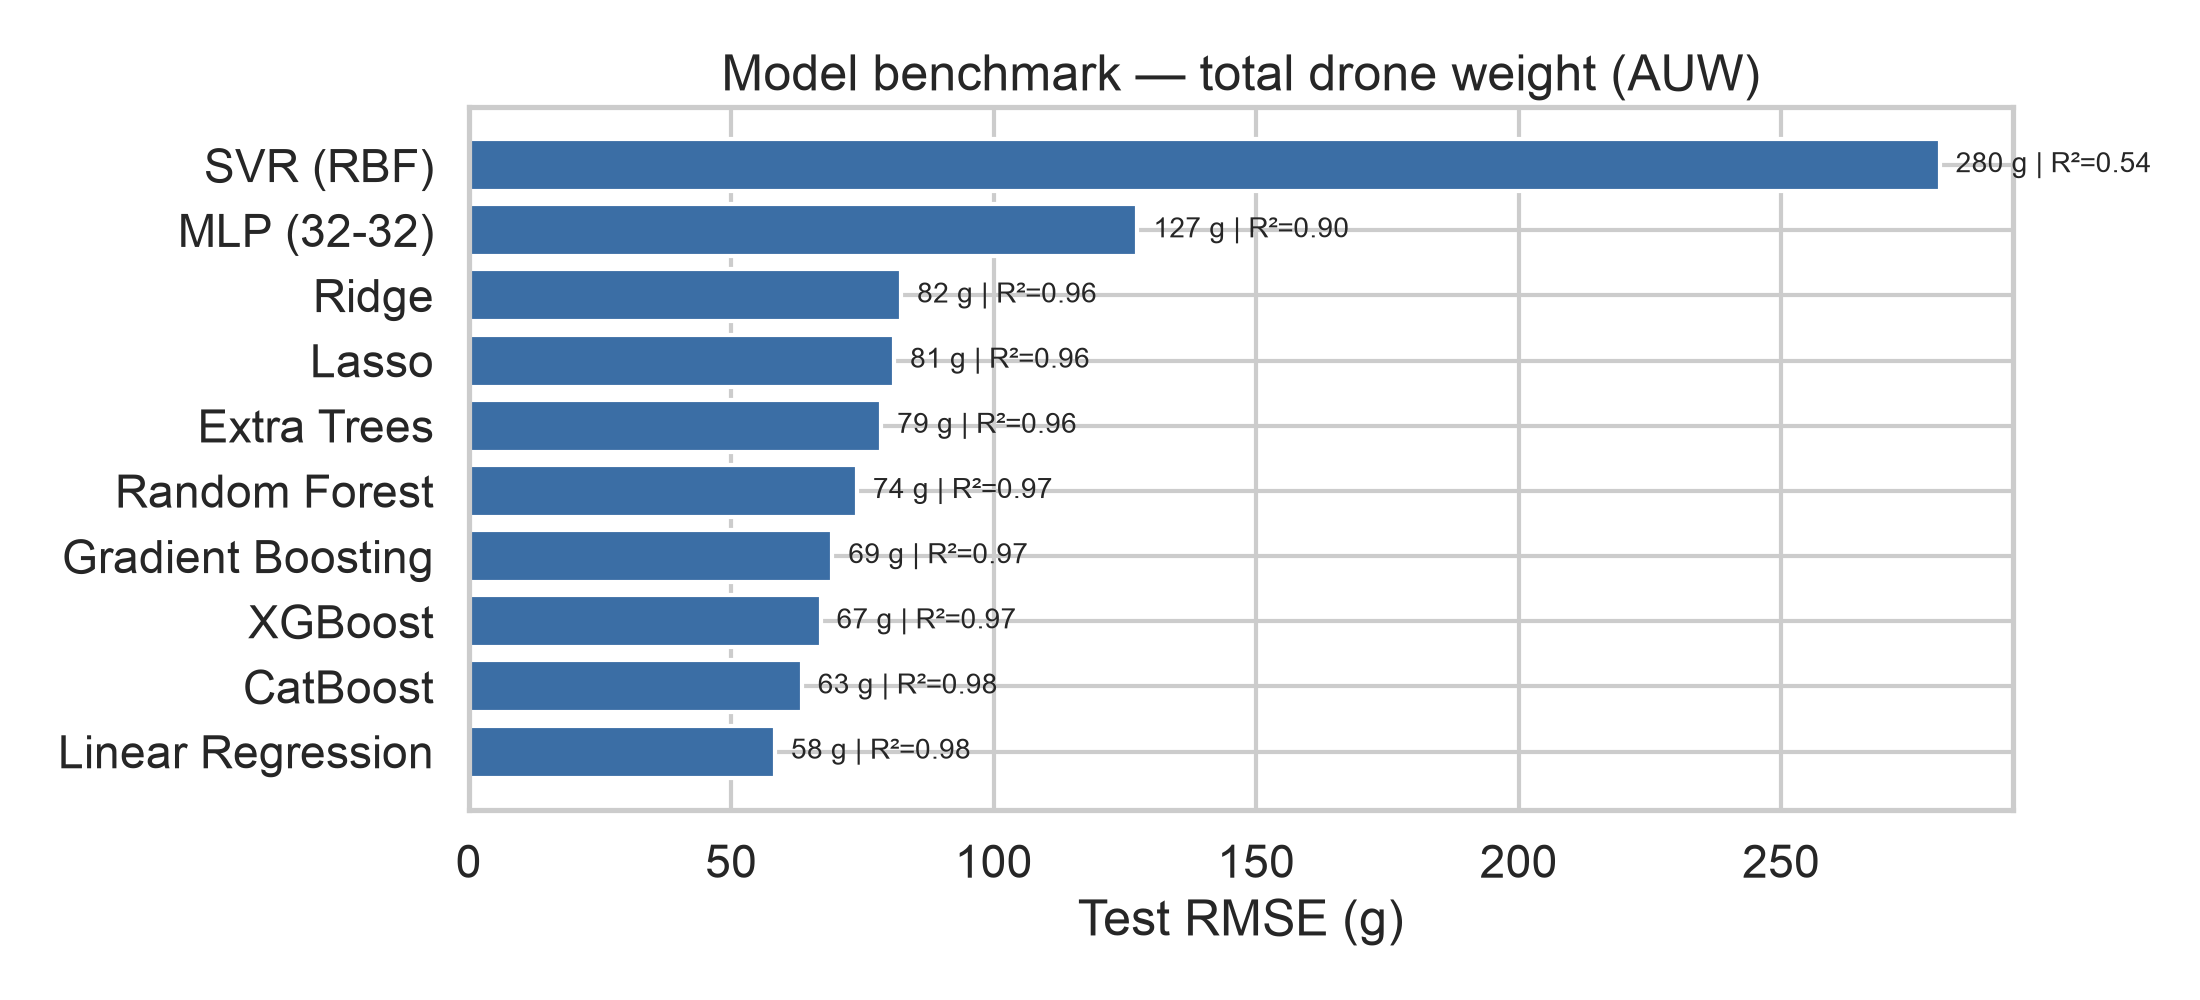

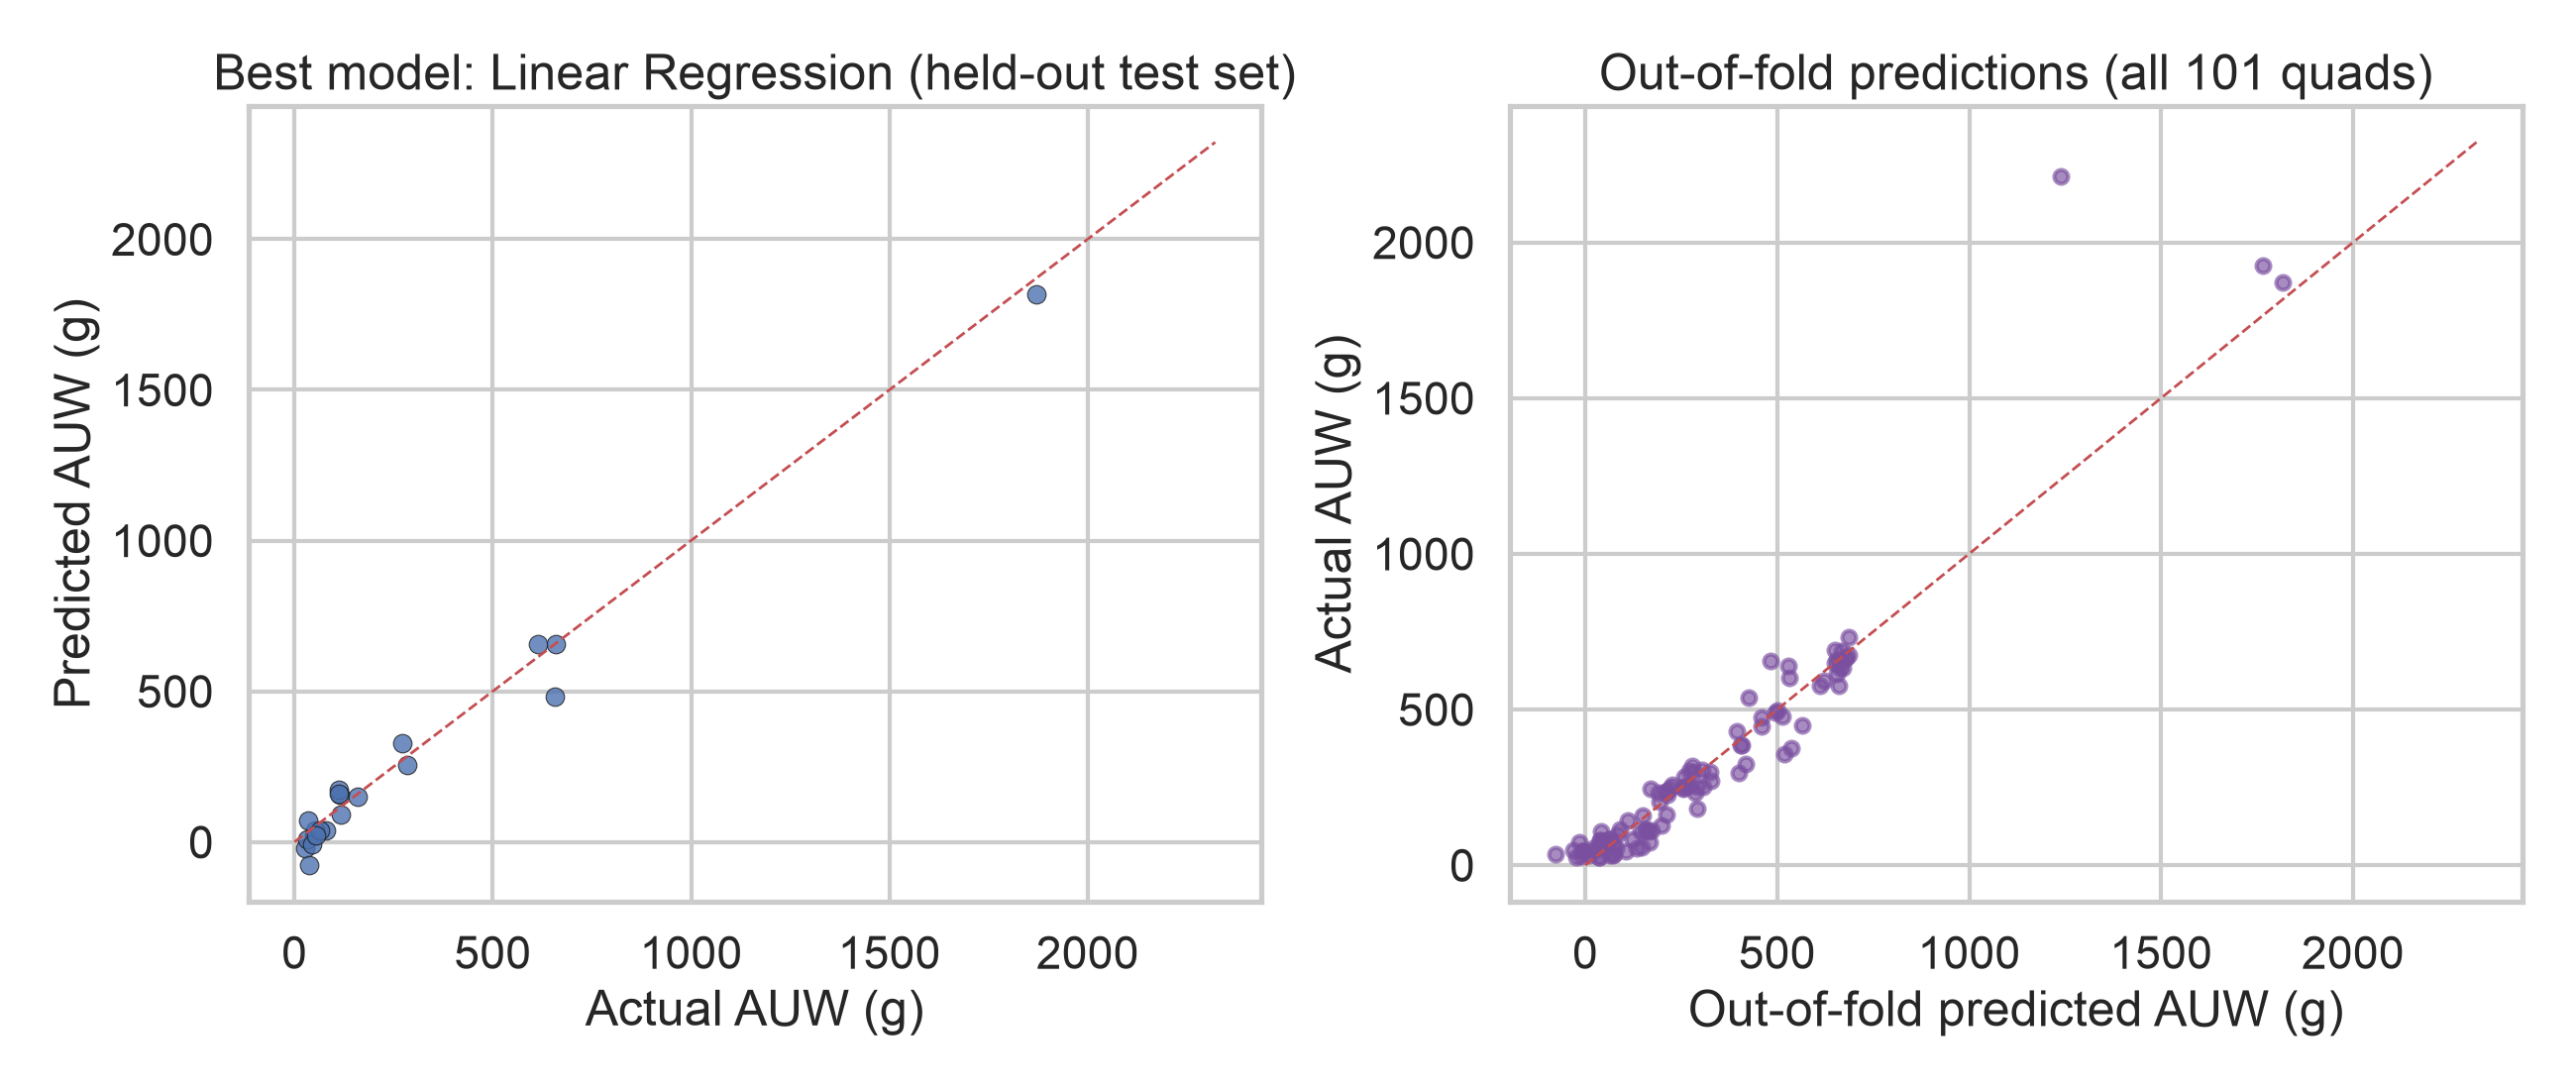

In [3]:
plots(metrics, artefacts)
from IPython.display import Image, display
display(Image(filename="../outputs/drone_weight/figures/model_rmse_comparison.png", width=850))
display(Image(filename="../outputs/drone_weight/figures/predicted_vs_actual.png", width=850))

## Interpretation

* **Linear regression is the most stable** (CV R² 0.902 ± 0.074) and has the lowest test
  RMSE. With 101 samples, the extra flexibility of boosted trees does not pay for itself.
* **CatBoost has the best absolute error** (MAE 39.4 g, MAPE 20.6 %): gradient boosting
  captures the step-like motor/prop classes better than a straight line, at the cost of
  higher variance across folds.
* **The test R² (0.98) is optimistic** relative to repeated CV (0.90). The honest
  generalisation estimate is the CV column, not the single split.
* **SVR fails** (CV R² 0.67 ± 0.25): the RBF width cannot be tuned reliably at n = 101.
* **Neural networks are not supported** by this dataset size; the small MLP is reported
  only to demonstrate that (R² 0.905, MAE 79 g).

**Engineering reading.** Weight is predictable to roughly ±40–80 g, i.e. 10–25 % of a
typical quad. That is good enough for early sizing but not for certification. It also
justifies using measured catalogue values, not model predictions, inside the optimizer.

In [4]:
metrics.to_csv("../outputs/drone_weight/model_benchmark_notebook.csv", index=False)
print("saved")

saved
